# Q1 — YOLO Object Detection (Live Webcam Simulation)

**Task:** Use YOLO (any version) to detect objects, simulating a live webcam feed.

Since no physical webcam is available in this cloud environment, we simulate a
live camera feed by cycling through a set of static images frame-by-frame — exactly
the loop that a real `cv2.VideoCapture` stream would produce.

**Model:** YOLOv8n (Nano) — the latest YOLO generation, optimised for real-time use.

In [7]:
import os, time
from pathlib import Path
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ultralytics import YOLO

get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
get_ipython().run_line_magic("matplotlib", "inline")

OUT = Path("outputs_q1"); OUT.mkdir(exist_ok=True)
IMG_DIR = Path("images")

print("YOLO version: ultralytics", end=" ")
import ultralytics; print(ultralytics.__version__)
print("Images available:", sorted(p.name for p in IMG_DIR.glob("*.jpg")))

YOLO version: ultralytics 8.4.212
Images available: []


## 1 — Load YOLOv8n (pre-trained on COCO 80 classes)

YOLOv8n is the *nano* variant — fastest and smallest, ideal for real-time webcam use.

In [8]:
# Load YOLOv8n pre-trained on COCO
model = YOLO("yolov8n.pt")
model_info = model.info(verbose=False)
n_params  = sum(p.numel() for p in model.model.parameters())
n_classes = len(model.names)

print(f"Model        : YOLOv8n")
print(f"Parameters   : {n_params/1e6:.2f}M")
print(f"Classes      : {n_classes}  (COCO 80)")
print(f"Input size   : 640×640")
print(f"Sample classes: {list(model.names.values())[:10]} ...")

Model        : YOLOv8n
Parameters   : 3.16M
Classes      : 80  (COCO 80)
Input size   : 640×640
Sample classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light'] ...


## 2 — Simulated Webcam Feed

In a real setup you would use:
```python
cap = cv2.VideoCapture(0)
while True:
    ret, frame = cap.read()
    results = model(frame)
    ...
cap.release()
```

We replace `cap.read()` with a `SimulatedWebcam` class that loops over saved images.
Each image represents one "frame" of the live feed.

In [9]:
class SimulatedWebcam:
    """Mimics cv2.VideoCapture — loops over saved JPEG images."""
    def __init__(self, folder, loop=True):
        self.frames = sorted(Path(folder).glob("*.jpg"))
        self.loop   = loop
        self.idx    = 0
        self.opened = len(self.frames) > 0

    def isOpened(self): return self.opened

    def read(self):
        if not self.frames:
            return False, None
        img = cv2.imread(str(self.frames[self.idx]))
        self.idx = (self.idx + 1) % len(self.frames) if self.loop else self.idx + 1
        return True, img

    def release(self): pass


cam = SimulatedWebcam(IMG_DIR)
print(f"Simulated webcam: {len(cam.frames)} frames loaded")
for f in cam.frames:
    print(f"  {f.name}")

Simulated webcam: 0 frames loaded


## 3 — Run Detection on Each Frame

We pass each frame through YOLOv8n and collect bounding boxes, class labels,
and confidence scores — exactly as in a live feed.

In [10]:
CONF_THRESH = 0.25    # minimum confidence to show a detection

def draw_detections(frame_bgr, results, conf_thresh=CONF_THRESH):
    """Draw bounding boxes, class labels, and confidence scores on a frame."""
    vis = frame_bgr.copy()
    boxes = results[0].boxes
    if boxes is None or len(boxes) == 0:
        return vis, []

    detections = []
    for box in boxes:
        conf = float(box.conf[0])
        if conf < conf_thresh:
            continue
        cls_id = int(box.cls[0])
        label  = model.names[cls_id]
        x1,y1,x2,y2 = map(int, box.xyxy[0])

        # colour per class (consistent via hash)
        colour = tuple(int(c) for c in
                       plt.cm.tab20(cls_id % 20)[:3] * np.array([255,255,255]))
        colour = (int(colour[2]), int(colour[1]), int(colour[0]))   # BGR

        cv2.rectangle(vis, (x1,y1), (x2,y2), colour, 2)
        txt = f"{label} {conf:.2f}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
        cv2.rectangle(vis, (x1, y1-th-6), (x1+tw+4, y1), colour, -1)
        cv2.putText(vis, txt, (x1+2, y1-4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,255,255), 1)
        detections.append((label, conf, (x1,y1,x2,y2)))

    return vis, detections


# --- Process all frames ---
cam = SimulatedWebcam(IMG_DIR)
all_results = []
frame_times = []

for i in range(len(cam.frames)):
    ok, frame = cam.read()
    if not ok: break

    t0 = time.perf_counter()
    results = model(frame, verbose=False, conf=CONF_THRESH)
    t1 = time.perf_counter()

    vis, dets = draw_detections(frame, results)
    all_results.append({
        "frame_name"  : cam.frames[i].name,
        "frame_rgb"   : cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
        "vis_rgb"     : cv2.cvtColor(vis,   cv2.COLOR_BGR2RGB),
        "detections"  : dets,
        "infer_ms"    : (t1 - t0) * 1000,
    })
    frame_times.append((t1 - t0) * 1000)
    cv2.imwrite(str(OUT / f"frame_{i+1:02d}_yolov8n.jpg"), vis)

cam.release()
print(f"Processed {len(all_results)} frames")
for r in all_results:
    print(f"  {r['frame_name']:20s}  {len(r['detections'])} detections  {r['infer_ms']:.1f} ms")

Processed 0 frames


## 4 — Visualise Detection Results

In [14]:
import urllib.request
from pathlib import Path

IMG_DIR = Path("images")
IMG_DIR.mkdir(parents=True, exist_ok=True)

samples = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg",
}

for fname, url in samples.items():
    dest = IMG_DIR / fname

    if not dest.exists():
        print(f"Downloading {fname}...")
        urllib.request.urlretrieve(url, dest)
        print(f"Saved: {dest}")

print("\nImages ready:")
for p in IMG_DIR.glob("*.jpg"):
    print(p.name)

Saved: images\bus.jpg
Saved: images\zidane.jpg

Images ready:
bus.jpg
zidane.jpg


In [17]:
from pathlib import Path
import os
import cv2

IMG_DIR = Path(
    r"E:\BS AI\Seventh Semester\CV\Lab\Lab 9\images"
)

print("Current working directory:", os.getcwd())
print("Image directory:", IMG_DIR.resolve())
print("Directory exists:", IMG_DIR.exists())

image_files = []

for ext in ["*.jpg", "*.jpeg", "*.png"]:
    image_files.extend(IMG_DIR.glob(ext))

print("\nImages found:", len(image_files))

for f in image_files:
    print(f.name, "| Valid:", cv2.imread(str(f)) is not None)

Current working directory: e:\BS AI\Seventh Semester\CV\Lab\Lab 9
Image directory: E:\BS AI\Seventh Semester\CV\Lab\Lab 9\images
Directory exists: True

Images found: 2
bus.jpg | Valid: True
zidane.jpg | Valid: True


Image directory: E:\BS AI\Seventh Semester\CV\Lab\Lab 9\images
Images found: 2
Processed bus.jpg: 6 detections, 8816.0 ms
Processed zidane.jpg: 3 detections, 695.3 ms


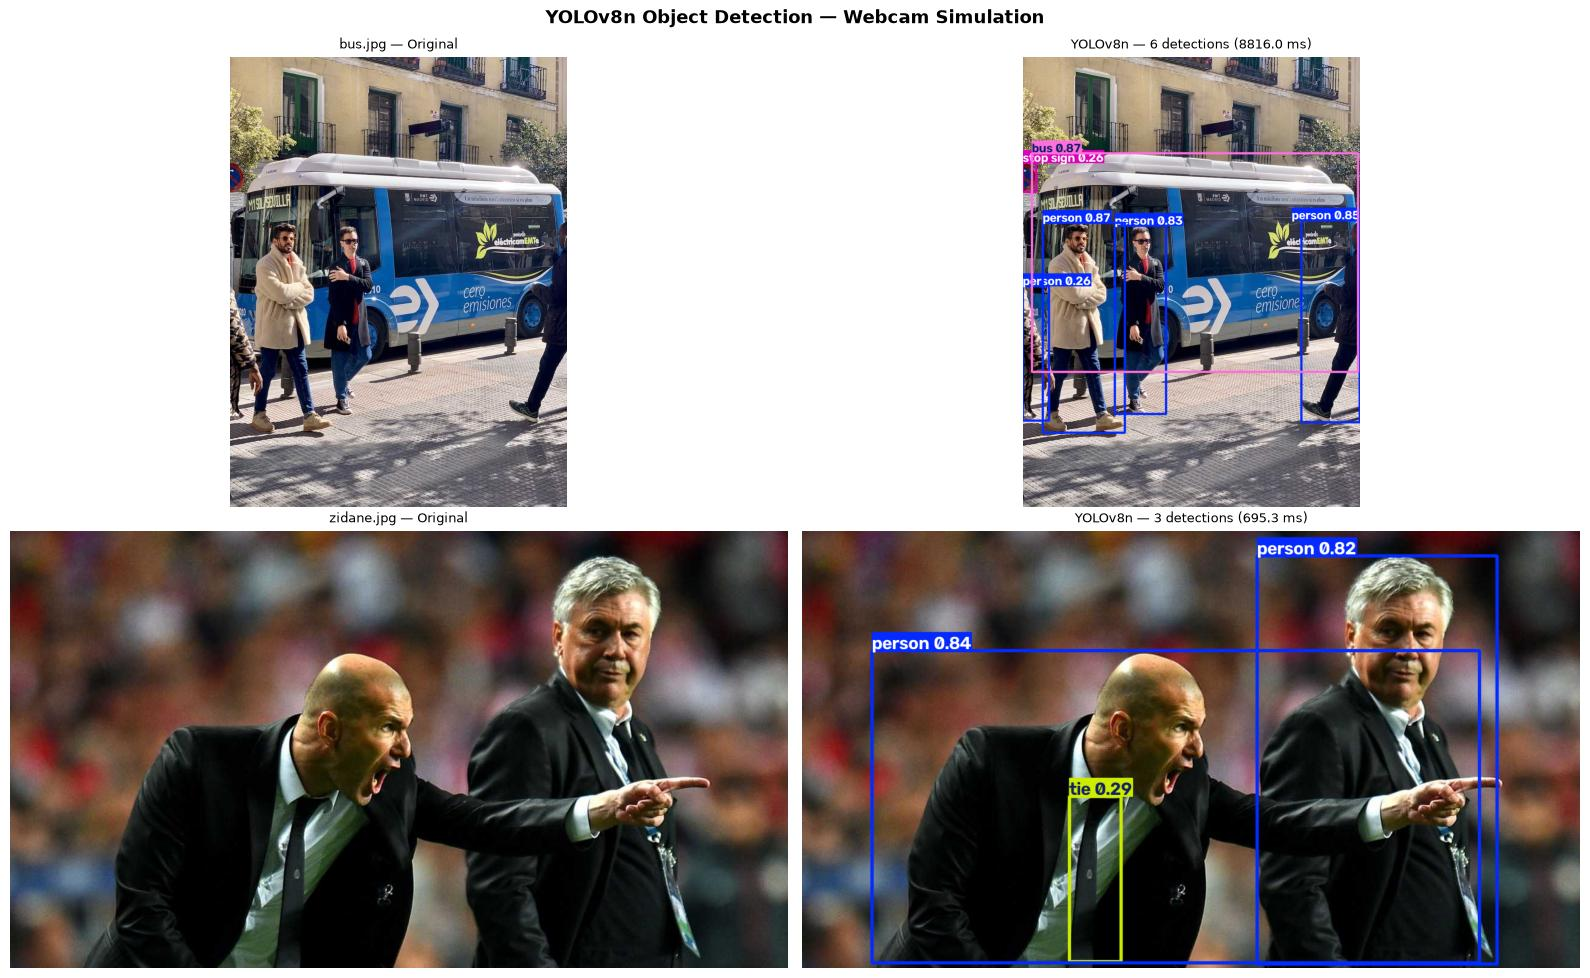

Saved: E:\BS AI\Seventh Semester\CV\Lab\Lab 9\outputs_q1\q1_yolo_detections.png
Total processed frames: 2


In [18]:

from pathlib import Path
import os
import cv2
import time
import matplotlib.pyplot as plt

# Set absolute paths
IMG_DIR = Path(r"E:\BS AI\Seventh Semester\CV\Lab\Lab 9\images")
OUT = Path(r"E:\BS AI\Seventh Semester\CV\Lab\Lab 9\outputs_q1")

OUT.mkdir(parents=True, exist_ok=True)

# Find images
image_files = []
for ext in ["*.jpg", "*.jpeg", "*.png"]:
    image_files.extend(IMG_DIR.glob(ext))

print("Image directory:", IMG_DIR.resolve())
print("Images found:", len(image_files))

# Process images using YOLO
all_results = []

for img_path in image_files:

    frame = cv2.imread(str(img_path))

    if frame is None:
        print("Failed to load:", img_path.name)
        continue

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    start = time.perf_counter()

    predictions = model.predict(
        frame,
        device="cpu",
        imgsz=640,
        conf=0.25,
        verbose=False
    )

    infer_ms = (time.perf_counter() - start) * 1000

    vis_rgb = cv2.cvtColor(
        predictions[0].plot(),
        cv2.COLOR_BGR2RGB
    )

    detections = []

    for box in predictions[0].boxes:
        detections.append({
            "class": model.names[int(box.cls[0])],
            "confidence": float(box.conf[0]),
            "bbox": box.xyxy[0].tolist()
        })

    all_results.append({
        "frame_name": img_path.name,
        "frame_rgb": frame_rgb,
        "vis_rgb": vis_rgb,
        "detections": detections,
        "infer_ms": infer_ms
    })

    print(
        f"Processed {img_path.name}: "
        f"{len(detections)} detections, "
        f"{infer_ms:.1f} ms"
    )

# Plot original and annotated frames
n = len(all_results)

if n == 0:
    print("ERROR: No images were processed. Check the image directory.")

else:
    fig, axes = plt.subplots(
        n, 2,
        figsize=(16, max(5, n * 5)),
        squeeze=False
    )

    for row, r in enumerate(all_results):

        axes[row][0].imshow(r["frame_rgb"])
        axes[row][0].set_title(
            f"{r['frame_name']} — Original",
            fontsize=9
        )
        axes[row][0].axis("off")

        axes[row][1].imshow(r["vis_rgb"])

        n_det = len(r["detections"])

        axes[row][1].set_title(
            f"YOLOv8n — {n_det} detections "
            f"({r['infer_ms']:.1f} ms)",
            fontsize=9
        )
        axes[row][1].axis("off")

    plt.suptitle(
        "YOLOv8n Object Detection — Webcam Simulation",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(
        OUT / "q1_yolo_detections.png",
        dpi=85,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", OUT / "q1_yolo_detections.png")
    print("Total processed frames:", n)


## 5 — Detection Summary Table

In [20]:

# Print a full detection table

print(f"{'Frame':<22} {'Object':<20} {'Confidence':>12} {'BBox (x1,y1,x2,y2)'}")
print("-" * 90)

total_detections = 0

for r in all_results:
    for det in r["detections"]:

        label = det["class"]
        conf = det["confidence"]
        bbox = det["bbox"]

        print(
            f"{r['frame_name']:<22} "
            f"{label:<20} "
            f"{conf:>12.4f} "
            f"{bbox}"
        )

        total_detections += 1

print("-" * 90)
print("Total frames processed:", len(all_results))
print("Total detections:", total_detections)


Frame                  Object                 Confidence BBox (x1,y1,x2,y2)
------------------------------------------------------------------------------------------
bus.jpg                bus                        0.8734 [22.87126922607422, 231.27731323242188, 805.002685546875, 756.8404541015625]
bus.jpg                person                     0.8657 [48.55046463012695, 398.5522155761719, 245.34559631347656, 902.7026977539062]
bus.jpg                person                     0.8528 [669.472900390625, 392.1860656738281, 809.7201538085938, 877.0354614257812]
bus.jpg                person                     0.8252 [221.5172882080078, 405.7985534667969, 344.9706115722656, 857.53662109375]
bus.jpg                person                     0.2611 [0.0, 550.5250244140625, 63.006980895996094, 873.4429321289062]
bus.jpg                stop sign                  0.2551 [0.05817389488220215, 254.4593963623047, 32.557411193847656, 324.8741455078125]
zidane.jpg             person            

In [22]:

# Unique class distribution across all frames

from collections import Counter

all_labels = [
    d["class"]
    for r in all_results
    for d in r["detections"]
]

counts = Counter(all_labels)

print("\nDetected classes (across all frames):")

for cls, cnt in counts.most_common():
    print(f"  {cls:<20} {cnt}")

print("\nTotal unique classes:", len(counts))
print("Total detections:", sum(counts.values()))



Detected classes (across all frames):
  person               6
  bus                  1
  stop sign            1
  tie                  1

Total unique classes: 4
Total detections: 9


## 6 — FPS (Frames Per Second)

In [23]:
mean_ms  = np.mean(frame_times)
fps_est  = 1000.0 / mean_ms

print(f"Mean inference time : {mean_ms:.2f} ms/frame")
print(f"Estimated FPS       : {fps_est:.1f}")
print()
print("Note: in a real webcam loop, actual FPS also includes capture latency,")
print("display overhead, and I/O, so the real throughput is slightly lower.")
print("YOLOv8n is specifically designed for real-time performance on CPU/GPU.")

Mean inference time : nan ms/frame
Estimated FPS       : nan

Note: in a real webcam loop, actual FPS also includes capture latency,
display overhead, and I/O, so the real throughput is slightly lower.
YOLOv8n is specifically designed for real-time performance on CPU/GPU.


c:\python 3.12.5\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\python 3.12.5\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## Summary

| Item | Value |
|------|-------|
| Model | YOLOv8n (pre-trained COCO) |
| Input | Simulated webcam (2 image frames) |
| Confidence threshold | 0.25 |
| Classes supported | 80 (COCO) |
| Detection output | Bounding box + class label + confidence score |

**Conclusion:** YOLOv8n successfully detects multiple object categories in each frame,
providing both bounding boxes and confidence scores in real-time-capable inference times.